# Analiza cantitativă a piețelor de energie — Cursul 4: Managementul riscului de preț pe piețele de energie
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București; Academia Română, Institutul de Prognoză Economică

Acest notebook Jupyter reproduce cifrele și graficele din cursul 4 pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe diapozitive.

**Convenții.** Factorul de risc este variația zilnică a prețului de bază pe piața pentru ziua următoare, $X_t=P_t-P_{t-1}$ (EUR/MWh), calculată pe calendarul complet (variația vecină cu o zi lipsă rămîne lipsă). Poziția: un furnizor care cumpără o bandă constantă și își bugetează costul la prețul de ieri; o creștere de preț este, deci, o pierdere. Prognoza pentru ziua $t$ folosește numai prețurile pînă în ziua $t-1$. Perioada analizată se încheie cu ultima lună completă.

## §1 Datele și factorul de risc

In [ ]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/notebooks')

cut-off: 2026-10-31 | missing RO days: 5 | valid RO changes: 4312


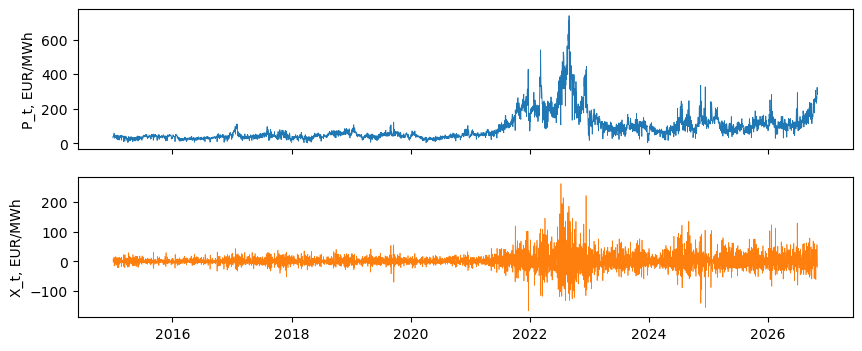

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings
from scipy import stats
from arch import arch_model
from joblib import Parallel, delayed
from statsmodels.regression.quantile_regression import QuantReg
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261106

PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
raw_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START, T0 = pd.Timestamp('2015-01-01'), pd.Timestamp('2017-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO', 'DE_LU']].reindex(CAL)       # missing days stay missing
X = P.diff()                               # a change next to a gap is NaN
print('cut-off:', END.date(), '| missing RO days:', int(P['RO'].isna().sum()), '| valid RO changes:', int(X['RO'].notna().sum()))
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(P['RO'], lw=0.6); ax[0].set_ylabel('P_t, EUR/MWh')
ax[1].plot(X['RO'], lw=0.5, color='C1'); ax[1].set_ylabel('X_t, EUR/MWh'); plt.show()

## §2 Repartiția variațiilor, VaR și ES și o limită calculată cu repartiția normală
VaR$_\alpha$ = cuantila de ordin $\alpha$ a pierderii; ES$_\alpha$ = pierderea medie la nivelul VaR sau dincolo de el.

In [2]:
def fl(x, k=4):
    if x is None:
        return None
    x = float(x)
    return None if np.isnan(x) else round(x, k)


def d(ts):
    return pd.Timestamp(ts).strftime("%Y-%m-%d")


def dist_facts(x, cal_end=None):
    """Moments and tail counts of a series of daily changes."""
    x = x.dropna()
    m, s = x.mean(), x.std()
    z3 = m + 3 * s
    zmax = (x.max() - m) / s
    lp = stats.norm.logsf(zmax) / np.log(10)                    # log10 P(Z > zmax)
    return {"n": int(len(x)), "mean": fl(m, 3), "sd": fl(s, 3), "skew": fl(stats.skew(x), 3),
            "exkurt": fl(stats.kurtosis(x), 2), "q99": fl(x.quantile(0.99), 2), "q01": fl(x.quantile(0.01), 2),
            "q99_normal": fl(m + stats.norm.ppf(0.99) * s, 2),
            "n_3sd_up": int((x > z3).sum()), "n_3sd_down": int((x < m - 3 * s).sum()),
            "exp_3sd": fl(len(x) * stats.norm.sf(3), 2), "max": fl(x.max(), 2), "max_date": d(x.idxmax()),
            "min": fl(x.min(), 2), "min_date": d(x.idxmin()), "max_z": fl(zmax, 1),
            "max_logyears": int(np.floor(-lp - np.log10(365.25)))}


for z in ['RO', 'DE_LU']:
    print(z, dist_facts(X[z]))

# empirical VaR and ES of the last 365 days, 100 MW flat = 2,400 MWh per day
last = X['RO'][END - pd.Timedelta(days=364):END].dropna()
v99, v975 = np.quantile(last, 0.99), np.quantile(last, 0.975)
print('VaR99 %.2f EUR/MWh = %.0f EUR for 100 MW | VaR97.5 %.2f | ES97.5 %.2f' % (v99, v99 * 2400, v975, last[last >= v975].mean()))

# a normal 99% limit estimated on 2015-2020 and its breaches afterwards
pre = X['RO']['2015':'2020'].dropna(); lim = pre.mean() + stats.norm.ppf(0.99) * pre.std()
for a, b in [('2015', '2020'), ('2021', '2022'), ('2023', str(END.year))]:
    x_ = X['RO'][a:b].dropna(); print(a, '-', b, 'breaches', int((x_ > lim).sum()), 'expected %.1f' % (0.01 * len(x_)))

RO {'n': 4312, 'mean': 0.063, 'sd': 25.84, 'skew': 1.024, 'exkurt': 11.97, 'q99': 88.21, 'q01': -70.74, 'q99_normal': 60.18, 'n_3sd_up': 52, 'n_3sd_down': 39, 'exp_3sd': 5.82, 'max': 260.77, 'max_date': '2022-07-11', 'min': -166.59, 'min_date': '2021-12-24', 'max_z': 10.1, 'max_logyears': 20}
DE_LU {'n': 4321, 'mean': 0.054, 'sd': 28.898, 'skew': 0.403, 'exkurt': 12.1, 'q99': 95.99, 'q01': -80.92, 'q99_normal': 67.28, 'n_3sd_up': 60, 'n_3sd_down': 37, 'exp_3sd': 5.83, 'max': 257.43, 'max_date': '2022-07-11', 'min': -232.67, 'min_date': '2022-10-01', 'max_z': 8.9, 'max_logyears': 16}
VaR99 86.63 EUR/MWh = 207922 EUR for 100 MW | VaR97.5 61.96 | ES97.5 86.91
2015 - 2020 breaches 45 expected 21.8
2021 - 2022 breaches 139 expected 7.3
2023 - 2026 breaches 226 expected 14.0


## §3 Cinci moduri de a estima VaR și ES, cu o zi înainte, pe fereastră glisantă
HS și metodele parametrice (normală, Student-$t$) pe ultimele 365 de zile; FHS = media zilei din săptămînă + volatilitatea GARCH(1,1) (reestimată la fiecare 21 de zile pe 730 de zile) + reziduurile standardizate empirice; EVT = același filtru + coada Pareto generalizată peste cuantila de 90% a reziduurilor. Motorul simulează și repartiția prognozată de fiecare model, necesară testului ES (§4).

In [3]:
METHODS = ['hs', 'normal', 't', 'fhs', 'evt']
LEVELS = (0.95, 0.975, 0.99)
W_HS, W_G, REFIT, U_EVT, M_SIM = 365, 730, 21, 0.90, 2000


def var_es_normal(w, a):
    m, s = np.mean(w), np.std(w, ddof=1)
    z = stats.norm.ppf(a)
    return m + s * z, m + s * stats.norm.pdf(z) / (1 - a)


def fit_t(w):
    nu, loc, sc = stats.t.fit(w)
    if nu < 2.2:
        nu = 2.2
        _, loc, sc = stats.t.fit(w, f0=nu)
    return nu, loc, sc


def var_es_t(par, a):
    nu, loc, sc = par
    q = stats.t.ppf(a, nu)
    es = stats.t.pdf(q, nu) / (1 - a) * (nu + q ** 2) / (nu - 1)
    return loc + sc * q, loc + sc * es


def var_es_hs(w, a):
    q = np.quantile(w, a)
    return q, w[w >= q].mean()


def gpd_tail(z, u_q=U_EVT):
    """Peaks over threshold on standardised residuals: threshold u, GPD shape xi and scale beta (MLE, location 0)."""
    u = np.quantile(z, u_q)
    exc = z[z > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    return u, xi, beta, len(exc), len(z)


def var_es_evt(tail, a):
    u, xi, beta, nu_, n = tail
    r = (n / nu_) * (1 - a)
    if abs(xi) < 1e-6:
        v = u - beta * np.log(r)
        return v, v + beta
    v = u + beta / xi * (r ** (-xi) - 1)
    return v, (v + beta - xi * u) / (1 - xi)


def garch_filter(e):
    """GARCH(1,1) with zero mean on the de-meaned changes (QMLE, normal); returns parameters and in-sample sigma."""
    res = arch_model(e, mean="Zero", vol="GARCH", p=1, q=1, dist="normal", rescale=False).fit(disp="off")
    om, al, be = res.params["omega"], res.params["alpha[1]"], res.params["beta[1]"]
    return float(om), float(al), float(be), np.asarray(res.conditional_volatility)


def run_zone(x, zone, seed=SEED):
    """Rolling one-day-ahead VaR/ES of a buyer's loss X_t for every day from T0 to END, five methods."""
    rng = np.random.default_rng(seed)
    days = pd.date_range(T0, END, freq="D")
    xs = x.copy()
    out = {m: {a: {"var": np.full(len(days), np.nan), "es": np.full(len(days), np.nan)} for a in LEVELS} for m in METHODS}
    sig = np.full(len(days), np.nan)
    mu_d = np.full(len(days), np.nan)
    z2c = {m: [] for m in METHODS}                   # per-day simulated Z2 contributions (M_SIM) and observed one
    z2o = {m: np.full(len(days), np.nan) for m in METHODS}
    tailinfo = []
    a_es = 0.975
    state = None
    for k, t in enumerate(days):
        hist = xs[:t - pd.Timedelta(days=1)].dropna()
        w = hist.values[-W_HS:]
        # ---- unconditional methods
        tpar = fit_t(w)
        for a in LEVELS:
            out["hs"][a]["var"][k], out["hs"][a]["es"][k] = var_es_hs(w, a)
            out["normal"][a]["var"][k], out["normal"][a]["es"][k] = var_es_normal(w, a)
            out["t"][a]["var"][k], out["t"][a]["es"][k] = var_es_t(tpar, a)
        # ---- filter: refit every REFIT days
        if k % REFIT == 0:
            hw = hist[-W_G:]
            mdow = hw.groupby(hw.index.dayofweek).mean()
            e = (hw - mdow.reindex(hw.index.dayofweek).values).values
            om, al, be, sw = garch_filter(e)
            z = e / sw
            state = {"om": om, "al": al, "be": be, "mdow": mdow, "z": np.sort(z), "tail": gpd_tail(z),
                     "s2": sw[-1] ** 2, "e": e[-1], "tlast": hw.index[-1]}
            tailinfo.append((d(t), state["tail"][1], state["tail"][2]))
        # advance sigma from the last day used to t-1, then one step to t
        while state["tlast"] < t - pd.Timedelta(days=1):
            nxt = state["tlast"] + pd.Timedelta(days=1)
            state["s2"] = state["om"] + state["al"] * state["e"] ** 2 + state["be"] * state["s2"]
            xv = xs.get(nxt, np.nan)
            state["e"] = (xv - state["mdow"][nxt.dayofweek]) if not np.isnan(xv) else 0.0
            if np.isnan(xv):          # missing day: expected shock (sigma^2 itself) instead of e^2
                state["e"] = np.sqrt(state["s2"])
            state["tlast"] = nxt
        s_t = np.sqrt(state["om"] + state["al"] * state["e"] ** 2 + state["be"] * state["s2"])
        m_t = state["mdow"][t.dayofweek]
        sig[k], mu_d[k] = s_t, m_t
        z = state["z"]
        for a in LEVELS:
            qz = np.quantile(z, a)
            out["fhs"][a]["var"][k] = m_t + s_t * qz
            out["fhs"][a]["es"][k] = m_t + s_t * z[z >= qz].mean()
            ve, ee = var_es_evt(state["tail"], a)
            out["evt"][a]["var"][k], out["evt"][a]["es"][k] = m_t + s_t * ve, m_t + s_t * ee
        # ---- Z2 contributions: simulated from each model's own predictive distribution, and observed
        xt = xs.get(t, np.nan)
        u, xi, beta, nu_, n_ = state["tail"]
        sims = {"hs": rng.choice(w, M_SIM), "normal": np.mean(w) + np.std(w, ddof=1) * rng.standard_normal(M_SIM),
                "t": tpar[1] + tpar[2] * rng.standard_t(tpar[0], M_SIM),
                "fhs": m_t + s_t * rng.choice(z, M_SIM)}
        zb = rng.choice(z[z <= u], M_SIM)
        up = rng.random(M_SIM) < nu_ / n_
        zb[up] = u + stats.genpareto.rvs(xi, scale=beta, size=up.sum(), random_state=rng)
        sims["evt"] = m_t + s_t * zb
        for mth in METHODS:
            v, es = out[mth][a_es]["var"][k], out[mth][a_es]["es"][k]
            ls = sims[mth]
            z2c[mth].append(np.where(ls > v, ls, 0.0) / es)
            if not np.isnan(xt):
                z2o[mth][k] = (xt if xt > v else 0.0) / es
    return {"days": days, "out": out, "sig": sig, "mu": mu_d, "z2c": {m: np.array(v, dtype=np.float32) for m, v in z2c.items()},
            "z2o": z2o, "tail": tailinfo, "zone": zone}


res = Parallel(n_jobs=2)(delayed(run_zone)(X[z], z, SEED + i) for i, z in enumerate(['RO', 'DE_LU']))
ENG = {r['zone']: r for r in res}; DAYS = ENG['RO']['days']
LM_ = DAYS >= END.replace(day=1)
tab = pd.DataFrame({m: {'VaR95': ENG['RO']['out'][m][0.95]['var'][LM_].mean(), 'VaR99': ENG['RO']['out'][m][0.99]['var'][LM_].mean(),
                        'ES97.5': ENG['RO']['out'][m][0.975]['es'][LM_].mean()} for m in METHODS}).T
print('mean of the forecasts for', END.strftime('%Y-%m'), '(EUR/MWh)'); print(tab.round(2))

mean of the forecasts for 2026-10 (EUR/MWh)
        VaR95  VaR99  ES97.5
hs      50.38  86.63   87.59
normal  49.33  69.64   69.98
t       45.77  76.66   80.05
fhs     36.22  67.50   67.44
evt     35.66  64.33   68.54


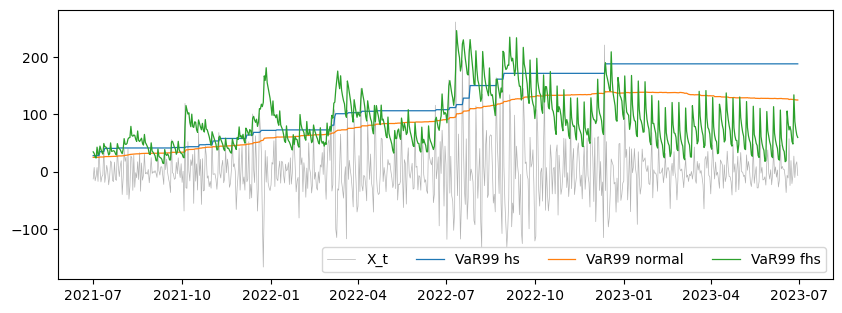

RO 10-day / 1-day 99% quantile: 1.72 (sqrt(10) = 3.16)
DE_LU 10-day / 1-day 99% quantile: 1.75 (sqrt(10) = 3.16)


In [4]:
# 99% VaR paths in the crisis, and the square-root-of-time check
a0, a1 = '2021-07-01', '2023-06-30'
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(X['RO'][a0:a1], color='0.7', lw=0.5, label='X_t')
for m in ['hs', 'normal', 'fhs']:
    ax.plot(pd.Series(ENG['RO']['out'][m][0.99]['var'], index=DAYS)[a0:a1], lw=0.9, label='VaR99 ' + m)
ax.legend(ncol=4); plt.show()
for z in ['RO', 'DE_LU']:
    p = P[z]; q1 = (p.shift(-1) - p).dropna().quantile(0.99)
    print(z, '10-day / 1-day 99%% quantile: %.2f (sqrt(10) = %.2f)' % ((p.shift(-10) - p).dropna().quantile(0.99) / q1, np.sqrt(10)))

## §4 Testarea retrospectivă: Kupiec, Christoffersen, semaforul Basel, Acerbi–Székely $Z_2$

In [5]:
def kupiec(hits, p0):
    n, x = len(hits), int(np.sum(hits))
    ph = x / n
    ll0 = (n - x) * np.log(1 - p0) + x * np.log(p0)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0.0) if 0 < ph < 1 else 0.0
    lr = -2 * (ll0 - ll1)
    return lr, float(stats.chi2.sf(lr, 1))


def christoffersen(hits):
    h = np.asarray(hits, int)
    a, b = h[:-1], h[1:]
    n00, n01 = int(np.sum((a == 0) & (b == 0))), int(np.sum((a == 0) & (b == 1)))
    n10, n11 = int(np.sum((a == 1) & (b == 0))), int(np.sum((a == 1) & (b == 1)))
    p01 = n01 / max(n00 + n01, 1)
    p11 = n11 / max(n10 + n11, 1)
    p = (n01 + n11) / (n00 + n01 + n10 + n11)

    def ll(q, k0, k1):
        return (k0 * np.log(1 - q) if k0 else 0.0) + (k1 * np.log(q) if k1 else 0.0)
    lr = -2 * (ll(p, n00 + n10, n01 + n11) - ll(p01, n00, n01) - ll(p11, n10, n11))
    return lr, float(stats.chi2.sf(lr, 1)), {"n00": n00, "n01": n01, "n10": n10, "n11": n11, "p01": p01, "p11": p11}


def zone_of(c):
    return "green" if c <= 4 else ("yellow" if c <= 9 else "red")


rows = []
for z in ['RO', 'DE_LU']:
    E = ENG[z]; x = X[z].reindex(DAYS).values; ok = ~np.isnan(x)
    for m in METHODS:
        r = {'zone': z, 'method': m}
        for a in (0.95, 0.99):
            h = (x[ok] > E['out'][m][a]['var'][ok]).astype(int)
            r[f'rate{a}'] = 100 * h.mean(); r[f'kupiec_p{a}'] = kupiec(h, 1 - a)[1]
        r['christ_p0.99'] = christoffersen(h)[1]
        c250 = pd.Series(np.where(ok, (x > E['out'][m][0.99]['var']).astype(float), 0.0)).rolling(250).sum().iloc[249:]
        r['red_days_%'] = 100 * (c250.map(zone_of) == 'red').mean()
        T_ = ok.sum(); obs = np.nansum(E['z2o'][m][ok]) / (T_ * 0.025) - 1
        sim = E['z2c'][m][ok].sum(0) / (T_ * 0.025) - 1
        r['Z2'] = obs; r['Z2_p'] = np.mean(sim >= obs)
        rows.append(r)
print(pd.DataFrame(rows).round(3).to_string(index=False))

 zone method  rate0.95  kupiec_p0.95  rate0.99  kupiec_p0.99  christ_p0.99  red_days_%    Z2  Z2_p
   RO     hs     6.161         0.002     2.035         0.000         0.682      16.727 0.628 0.000
   RO normal     7.360         0.000     3.206         0.000         0.868      29.473 1.425 0.000
   RO      t     8.754         0.000     1.979         0.000         0.630      18.253 0.908 0.000
   RO    fhs     5.576         0.120     1.505         0.005         0.199       6.194 0.335 0.004
   RO    evt     5.548         0.139     1.366         0.037         0.244       2.813 0.279 0.010
DE_LU     hs     6.377         0.000     1.671         0.000         0.998       9.156 0.529 0.000
DE_LU normal     6.656         0.000     2.980         0.000         0.332      16.278 1.250 0.000
DE_LU      t     8.326         0.000     1.866         0.000         0.174       9.037 0.617 0.001
DE_LU    fhs     5.820         0.028     1.615         0.001         0.948       2.663 0.305 0.008
DE_LU    e

## §5 Marjele la bursă: VaR istorică de 99% pe două zile pentru Brent ICE (RTS EMIR 153/2013)
Zilele de schimbare a contractului (prima zi de tranzacționare a fiecărei luni) sînt eliminate din randamente.

IM per lot on 2026-02-27: 5970 USD (12 months), 7896 (with floor)
max Jan-Jun 2026: 16313 (x2.73), with floor 16313 (x2.07)
largest one-day VM for 100 lots sold: 0.88 million USD on 2019-09-16


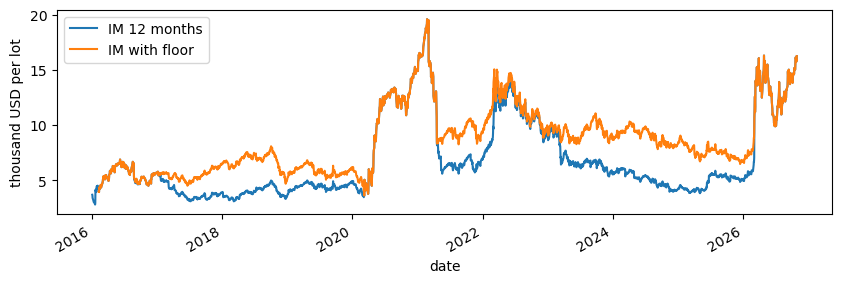

In [6]:
F = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')['brent_usd_bbl'].dropna()[:END]
ym = F.index.to_period('M'); roll = pd.Series(np.r_[False, ym[1:] != ym[:-1]], index=F.index)
r2 = F / F.shift(2) - 1; r2[(roll | roll.shift(1, fill_value=False))] = np.nan
IM1 = 1000 * F * r2.abs().rolling(250, min_periods=200).quantile(0.99)       # 12-month lookback
IML = 1000 * F * r2.abs().expanding(min_periods=250).quantile(0.99)          # floor: all data since 2015
IMA = np.maximum(IM1, IML)
pre = pd.Timestamp('2026-02-27')
print('IM per lot on %s: %.0f USD (12 months), %.0f (with floor)' % (pre.date(), IM1[pre], IMA[pre]))
print('max Jan-Jun 2026: %.0f (x%.2f), with floor %.0f (x%.2f)' % (IM1['2026-01':'2026-06'].max(), IM1['2026-01':'2026-06'].max() / IM1[pre],
      IMA['2026-01':'2026-06'].max(), IMA['2026-01':'2026-06'].max() / IMA[pre]))
vm = F.diff(); vm[roll] = np.nan; vm = vm * 1000 * 100                          # seller of 100 lots pays when the price rises
print('largest one-day VM for 100 lots sold: %.2f million USD on %s' % (vm.max() / 1e6, vm.idxmax().date()))
ax = (pd.DataFrame({'IM 12 months': IM1, 'IM with floor': IMA})['2016':] / 1000).plot(figsize=(10, 3)); ax.set_ylabel('thousand USD per lot'); plt.show()

## §6 Garanția pentru piața pentru ziua următoare dintr-o prognoză a cuantilei și limitele de poziție
Regresia cuantilică a lui $P_t$ pe $P_{t-1}$, $P_{t-7}$ și variabilele zilei din săptămînă (ultimele 365 de zile), apoi o corecție conformală unilaterală: cuantila de ordin $\tau$ a ultimelor 365 de erori din afara eșantionului.

In [7]:
PR = P['RO']; TAUS = (0.95, 0.99)


def qr_forecast(t, taus=TAUS, w=365):
    """Quantile regression of P_t on P_{t-1}, P_{t-7} and weekday dummies, last w days before t."""
    idx = pd.date_range(t - pd.Timedelta(days=w), t - pd.Timedelta(days=1), freq="D")
    df = pd.DataFrame({"y": PR.reindex(idx), "p1": PR.shift(1).reindex(idx), "p7": PR.shift(7).reindex(idx)})
    for j in range(6):
        df[f"d{j}"] = (idx.dayofweek == j).astype(float)
    df = df.dropna()
    Xm = np.column_stack([np.ones(len(df)), df[["p1", "p7"] + [f"d{j}" for j in range(6)]].values])
    xt = np.r_[1.0, PR.get(t - pd.Timedelta(days=1), np.nan), PR.get(t - pd.Timedelta(days=7), np.nan),
               [(t.dayofweek == j) * 1.0 for j in range(6)]]
    out = {}
    warnings.filterwarnings("ignore")
    for tau in taus:
        b = QuantReg(df["y"].values, Xm).fit(q=tau, max_iter=5000).params
        out[tau] = float(xt @ b)
    return out


QD = pd.date_range('2016-01-01', END, freq='D')
rr = Parallel(n_jobs=-1)(delayed(qr_forecast)(t) for t in QD)
QRF = pd.DataFrame({tau: [r_[tau] for r_ in rr] for tau in TAUS}, index=QD)
for tau in TAUS:
    cq = QRF[tau] + (PR.reindex(QD) - QRF[tau]).shift(1).rolling(365, min_periods=300).quantile(tau)
    fq = PR.shift(1).reindex(DAYS) + pd.Series(ENG['RO']['out']['fhs'][tau]['var'], index=DAYS)
    df = pd.DataFrame({'p': PR.reindex(DAYS), 'qr': QRF[tau].reindex(DAYS), 'cqr': cq.reindex(DAYS), 'fhs': fq}).dropna()
    print(tau, {k: round(100 * (df['p'] <= df[k]).mean(), 2) for k in ['qr', 'cqr', 'fhs']},
          'mean guarantee for 100 MW, million EUR/day: %.3f' % (df['cqr'].mean() * 2400 / 1e6))
v99 = pd.Series(ENG['RO']['out']['fhs'][0.99]['var'], index=DAYS)
qmax = 250_000 / (24 * v99)          # MW for a daily VaR budget of 250,000 EUR (an assumption)
print('position limit, MW: 2019 median %.0f | minimum %.0f on %s | last %.0f' % (qmax['2019'].median(), qmax.min(), qmax.idxmin().date(), qmax.iloc[-1]))

0.95 {'qr': np.float64(93.25), 'cqr': np.float64(94.28), 'fhs': np.float64(94.42)} mean guarantee for 100 MW, million EUR/day: 0.317
0.99 {'qr': np.float64(96.9), 'cqr': np.float64(98.47), 'fhs': np.float64(98.49)} mean guarantee for 100 MW, million EUR/day: 0.371
position limit, MW: 2019 median 514 | minimum 42 on 2022-07-12 | last 196


## §7 Costul lunar la risc al unui furnizor și coada producătorului

normal 99% limit 50.5% | exceeded 3 times since 2021 (0.7 expected)
worst month 2024-11 86.6%, 5.96 million EUR
daily 99% quantile (supplier) 88.21 | 1% quantile (producer) -70.74 | skewness 1.02


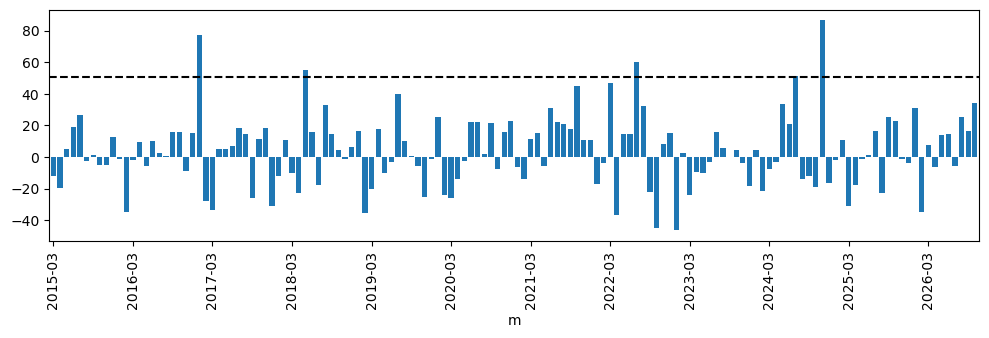

In [8]:
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')['RO']
GL = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')['load']
hl = pd.DataFrame({'p': HP, 'l': GL}).dropna()
hl['m'] = hl.index.tz_convert('Europe/Brussels').tz_localize(None).to_period('M')
mon = hl.groupby('m').apply(lambda g: pd.Series({'lwp': (g.p * g.l).sum() / g.l.sum(), 'base': g.p.mean(), 'hours': len(g)}))
mon = mon[(mon.index >= pd.Period('2015-02', 'M')) & (mon.index <= pd.Period(END, 'M'))]
mon['o'] = mon['lwp'] / mon['lwp'].shift(1) - 1
mon['eur'] = 100 * mon['hours'] * (mon['lwp'] - mon['lwp'].shift(1))
mon = mon.dropna()
pre = mon['o'][mon.index <= pd.Period('2020-12', 'M')]; lim = pre.mean() + stats.norm.ppf(0.99) * pre.std()
post = mon[mon.index >= pd.Period('2021-01', 'M')]
print('normal 99%% limit %.1f%% | exceeded %d times since 2021 (%.1f expected)' % (100 * lim, (post['o'] > lim).sum(), 0.01 * len(post)))
print('worst month', mon['o'].idxmax(), '%.1f%%, %.2f million EUR' % (100 * mon['o'].max(), mon.loc[mon['o'].idxmax(), 'eur'] / 1e6))
xr = X['RO'].dropna()
print('daily 99%% quantile (supplier) %.2f | 1%% quantile (producer) %.2f | skewness %.2f' % (xr.quantile(0.99), xr.quantile(0.01), stats.skew(xr)))
ax = (100 * mon['o']).plot(kind='bar', figsize=(12, 3), width=0.8); ax.axhline(100 * lim, ls='--', color='k')
ax.set_xticks(range(0, len(mon), 12)); ax.set_xticklabels([str(p_) for p_ in mon.index[::12]]); plt.show()

## §8 Studiu de caz: toamna anului 2026 — riscul de piață și riscul de lichiditate

hs 99% exceedances since 2026-06-01: 1 (expected 1.5)
normal 99% exceedances since 2026-06-01: 3 (expected 1.5)
t 99% exceedances since 2026-06-01: 2 (expected 1.5)
fhs 99% exceedances since 2026-06-01: 2 (expected 1.5)
evt 99% exceedances since 2026-06-01: 2 (expected 1.5)
mean price June 122.99, October 239.32 EUR/MWh
FHS VaR99 June 61.64, October 67.50
guarantee (conformal 99%) for 100 MW, million EUR/day: June 0.416, October 0.776
                o           eur
m                              
2026-08  0.251242  2.378479e+06
2026-09  0.162305  1.860543e+06
2026-10  0.339627  4.682240e+06


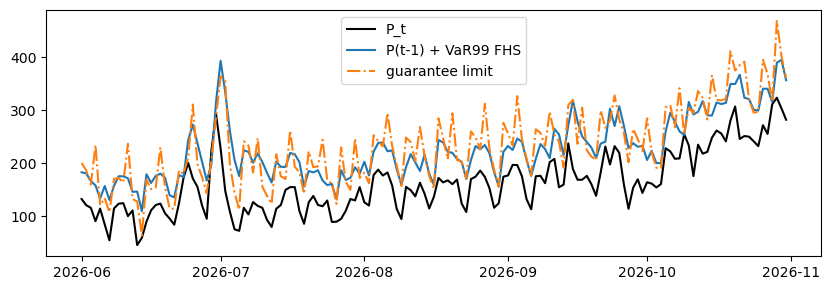

In [9]:
C0 = pd.Timestamp('2026-06-01'); x = X['RO'].reindex(DAYS)
for m in METHODS:
    v = pd.Series(ENG['RO']['out'][m][0.99]['var'], index=DAYS)
    print(m, '99%% exceedances since %s: %d (expected %.1f)' % (C0.date(), int((x[C0:] > v[C0:]).sum()), 0.01 * x[C0:].notna().sum()))
print('mean price June %.2f, October %.2f EUR/MWh' % (PR['2026-06'].mean(), PR['2026-10'].mean()))
print('FHS VaR99 June %.2f, October %.2f' % (v99['2026-06'].mean(), v99['2026-10'].mean()))
print('guarantee (conformal 99%%) for 100 MW, million EUR/day: June %.3f, October %.3f' % (cq['2026-06'].mean() * 2400 / 1e6, cq['2026-10'].mean() * 2400 / 1e6))
print(mon.loc[pd.Period('2026-08', 'M'):, ['o', 'eur']])
cc = pd.date_range(C0, END)
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.plot(cc, PR.reindex(cc), color='k', label='P_t')
ax.plot(cc, PR.shift(1).reindex(cc) + v99.reindex(cc), label='P(t-1) + VaR99 FHS'); ax.plot(cc, cq.reindex(cc), ls='-.', label='guarantee limit')
ax.legend(); plt.show()